In [1]:
import matplotlib.pyplot as plt
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import SGD
from torch.optim.lr_scheduler import StepLR
import torchvision.transforms.v2 as v2
from torchvision.datasets import FashionMNIST

In [2]:
data_path = Path.cwd().parent / "data"
data_path.exists()

True

In [3]:
# hyperparameters
batch_size = 32
lr = 0.05

In [4]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(dtype=torch.float32, scale=True)
])

In [5]:
train_dataset = FashionMNIST(
    root=data_path,
    train=True,
    transform=transform,
    download=False
)
test_dataset = FashionMNIST(
    root=data_path,
    train=False,
    transform=transform,
    download=False
)
print(f"{len(train_dataset) = }")
print(f"{len(test_dataset) = }")

len(train_dataset) = 60000
len(test_dataset) = 10000


In [6]:
train_loader = torch.utils.data.DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True
)
class_to_idx = train_dataset.class_to_idx
idx_to_class = {idx: cls for cls, idx in class_to_idx.items()}
num_classes = len(class_to_idx)
num_classes

10

In [7]:
x, y = next(iter(train_loader))
print(f"{x.shape = }")
print(f"{y.shape = }")

x.shape = torch.Size([32, 1, 28, 28])
y.shape = torch.Size([32])


In [8]:
# LeNet

In [11]:
class LeNet(nn.Module):

    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, padding=2), nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5), nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.Linear(in_features=400, out_features=120), nn.ReLU(),
            nn.Linear(in_features=120, out_features=84), nn.ReLU(),
            nn.Linear(in_features=84, out_features=num_classes)
        )
        self.apply(self.apply_init)

    def apply_init(self, m):
        if isinstance(m, (nn.Linear, nn.Conv2d)):
            nn.init.xavier_uniform_(m.weight)

            if m.bias is not None:
                nn.init.zeros_(m.bias)
        
    def forward(self, x):
        return self.net(x)

    def loss(self, y_hat, y):
        return F.cross_entropy(y_hat, y)

    def step(self, x, y):
        return self.loss(self(x), y)

    def training_step(self, x, y):
        return self.step(x, y)

    def validation_step(self, x, y):
        return self.step(x, y)

    def configure_optimizer(self, lr):
        return SGD(
            params=self.parameters(),
            lr=lr
        )
    
    def layer_summary(self, x_shape):
        x = torch.normal(0.0, 1.0, size=x_shape)
        for layer in self.net:
            x = layer(x)
            print(f"{layer.__class__.__name__} output shape:\t{x.shape}")

In [12]:
def calculate_accuracy():
    with torch.inference_mode():
        test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=len(test_dataset))
        x, y = next(iter(test_loader))

        logits = model(x)
        logits = logits - logits.max(dim=1, keepdim=True).values
        probs = logits.exp() / logits.exp().sum(dim=1, keepdim=True)
        preds = probs.max(dim=1).indices
        corrects = (preds == y).sum()
        accuracy = corrects / len(preds)

        return accuracy

In [13]:
# end = torch.log10(torch.tensor([0.4])).item()
# lrs = torch.logspace(-3, end, steps=len(train_loader))
# gamma = lrs[1] / lrs[0]
# scheduler = StepLR(optimizer, step_size=1, gamma=gamma)

def train(max_epoches):
    # with ReLU nonlinearity
    losses = torch.empty(size=(max_epoches, len(train_loader)))
    for epoch in range(max_epoches):
        for i, (x, y) in enumerate(train_loader):
            loss = model.training_step(x, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()        
            losses[epoch, i] = loss.item()
        scheduler.step()
        
        accuracy = calculate_accuracy() * 100
        print(f"epoch: {epoch+1}, training loss: {losses[epoch].mean():.2f}, accuracy: {accuracy:.2f}%")

    return losses

In [14]:
model = LeNet()
optimizer = model.configure_optimizer(lr=0.02)
scheduler = StepLR(optimizer, step_size=2, gamma=0.1)
training_losses = train(5)

epoch: 1, training loss: 0.71, accuracy: 82.81%
epoch: 2, training loss: 0.44, accuracy: 84.98%
epoch: 3, training loss: 0.36, accuracy: 86.16%
epoch: 4, training loss: 0.35, accuracy: 86.28%
epoch: 5, training loss: 0.34, accuracy: 86.60%


In [20]:
sum(param.nelement() for param in model.parameters())

61706

In [15]:
training_losses.shape

torch.Size([5, 1875])

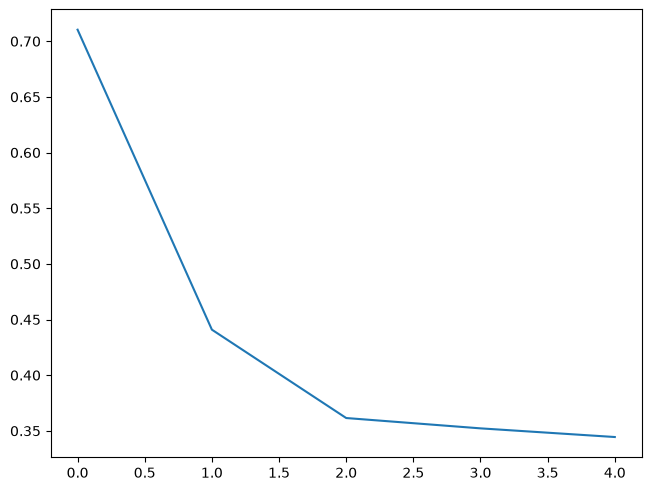

In [16]:
new_losses = training_losses.mean(dim=1)
fig, ax = plt.subplots(layout="constrained")
ax.plot(new_losses.numpy())
plt.show()

In [17]:
# visuilize the incorrect predictions
def visuilize_incorrect_predictions():
    test_dataloader = torch.utils.data.DataLoader(test_dataset, batch_size=32)
    with torch.inference_mode():
        x, y = next(iter(test_dataloader))
        logits = model(x)
        logits = logits - logits.max(dim=1, keepdim=True).values
        probs = logits.exp() / logits.exp().sum(dim=1, keepdim=True)
        y_pred = probs.max(dim=1).indices
    
    incorrects = y_pred != y
    incorrect_indices, = incorrects.nonzero(as_tuple=True)
    incorrect_y_preds = y_pred[incorrects]
    corresponding_correct_preds = y[incorrects]
    
    fig, axs = plt.subplots(ncols=len(incorrect_indices), figsize=(15, 3), layout="constrained")
    for i in range(len(incorrect_indices)):
        img, correct_label, pred_label = x[incorrect_indices[i]].squeeze(0), corresponding_correct_preds[i].item(), incorrect_y_preds[i].item()
        correct_class, pred_class = idx_to_class[correct_label], idx_to_class[pred_label]
    
        axs[i].imshow(img.numpy(), cmap="gray")
        axs[i].axis("off")
        axs[i].set_title(f"act: {correct_class}\npred: {pred_class}")
    plt.show()

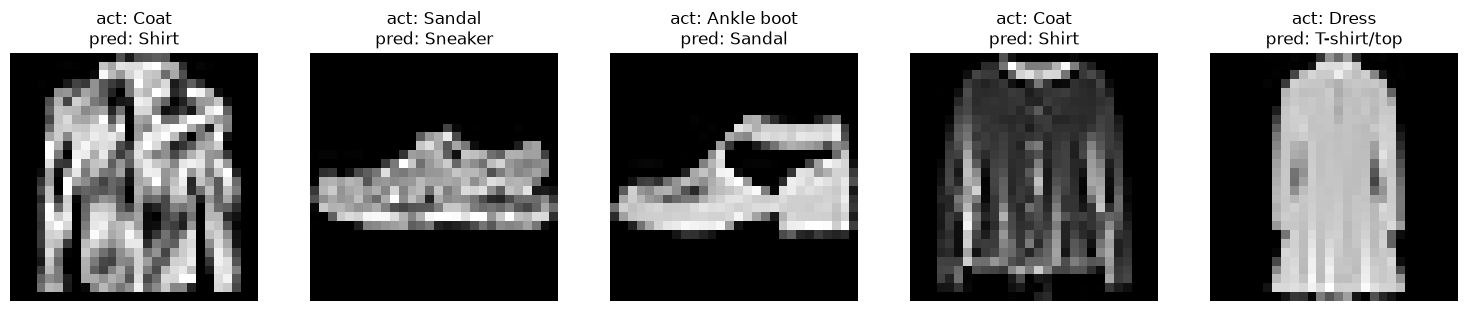

In [18]:
visuilize_incorrect_predictions()